# SiN Bent Waveguide -- Radius Sweep, Circular vs. Euler, and Comparison with Si

Second notebook of the **SiN track**, the counterpart of the Si track's
`si/notebooks/02_bent_waveguide.ipynb`. It characterizes 90° bends of the 400 nm SiN strip
from `01_sin_waveguide_baseline.ipynb` (0.9 µm wide, n_eff-matched 2D core index 1.7650). Both a circular arc and a gdsfactory
Euler bend are swept over radius. The result is first validated against published 3D
simulations and measurements, then compared with a Si strip modelled the same way.

The question this notebook answers: **how much larger must a SiN bend be than a Si bend
for the same loss, and why?**

1. **Component definition** -- parameters, bend-loss physics, resolution and domain.
2. **GDSFactory geometry** and 3. **geometry visualization**.
4. **2D Meep FDTD simulation** -- baselines at a representative radius, fields,
   S-parameters, radius sweep.
5. **SAX model fitting** -- loss and phase against radius, per bend type.
6. **Sanity checks**, 7. **save artifacts and design point**, 8. **the SAX model**.
9. **SiN vs. Si** -- the calibrated Si reference, validation against the literature,
   loss against radius, the radius needed for a given loss, fields, and the physics that
   sets the ratio.

Kernel: `mp` conda env, run from `sin/notebooks/`. The radius sweep takes several hours
of single-core FDTD; its artifacts are cached in `sin/data/sparams/sin_bend/sweep/`, and
the notebook reloads them.

**Do not use "Run All."** Work through the notebook step by step, and stop at the
marked checkpoints to actually look at the plots before continuing.

## 1. Component definition

**Governing relations.** As in the Si track, a bend of radius $R$ loses power through
**transition (mode-mismatch) loss** at each straight-to-arc junction and **radiation
loss** from the curved section. The radiation part falls off roughly exponentially with
$R$, so the same empirical form is fitted:
$$\mathrm{Loss}_{dB}(R) = \mathrm{Loss}_{dB,\infty} + A\, e^{-R/R_0}.$$

The decay radius $R_0$ is the number to compare between platforms. Section 9 links it to
the mode properties measured in `01_sin_waveguide_baseline.ipynb`.

In [1]:
import inspect
import json
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import quad
import yaml
import gdsfactory as gf

from pic_toolkit.params import SIN_GLOBAL_PARAMS, SI_REF_PARAMS
from pic_toolkit.meep_sim import bend
from pic_toolkit import checks, viz, sparams, design_points, sweep, style, slab_modes

style.apply_style()
%matplotlib inline

In [2]:
# bend.py's DEFAULT_PARAMS (arm length, port/source offsets, lead overrun) + the SiN
# parameter set, with two overrides measured for this platform (Section 1.1):
#   resolution 40 px/um -- the same as the Si bend, converged to ~1 % in loss here;
#   margin_um 2.0       -- the SiN mode tail is ~2x longer than the Si mode's.
REPRESENTATIVE_RADIUS_UM = 15.0
params = {**bend.DEFAULT_PARAMS, **SIN_GLOBAL_PARAMS,
          "resolution": 40, "margin_um": 2.0, "radius_um": REPRESENTATIVE_RADIUS_UM}

print("SiN parameter set (pic_toolkit.params.SIN_GLOBAL_PARAMS)")
print(f"  waveguide width      : {params['wg_width_um']} um")
print(f"  core / clad index    : {params['core_index']} / {params['clad_index']}  (2D effective index)")
print(f"  wavelength band      : {params['wl_min_um']}-{params['wl_max_um']} um")
print()
print("Component-specific parameters")
print(f"  resolution           : {params['resolution']} px/um")
print(f"  margin               : {params['margin_um']} um  (Si bend: 1.5)")
print(f"  representative radius: {params['radius_um']} um  (Si bend: 2.0)")
print(f"  arm length           : {params['arm_length_um']} um")

SiN parameter set (pic_toolkit.params.SIN_GLOBAL_PARAMS)
  waveguide width      : 0.9 um
  core / clad index    : 1.765 / 1.44  (2D effective index)
  wavelength band      : 1.3-1.4 um

Component-specific parameters
  resolution           : 40 px/um
  margin               : 2.0 um  (Si bend: 1.5)
  representative radius: 15.0 um  (Si bend: 2.0)
  arm length           : 3.0 um


### 1.1 Resolution and domain

The resolution was checked on circular bends before the sweep. The table gives the
insertion loss at 1.35 µm (details in `docs/simulation_settings_record.md`, SiN track
section).

The study was run with the plain slab-EIM core index 1.7786, before the calibration
described in notebook 01 §1.1. The calibrated 1.7650 differs by 0.8 %, which does not
change what grid is needed. The Si reference is checked separately at 40 vs. 60 px/µm
in §9.1.

| Radius | 20 px/µm | 30 px/µm | 40 px/µm | 60 px/µm |
|---|---|---|---|---|
| 5 µm | 2.848 dB | 2.944 dB | 2.968 dB | 2.993 dB |
| 15 µm | -- | 0.169 dB | 0.171 dB | -- |

From 40 to 60 px/µm the loss changes by 0.8 %. That is much smaller than the factor-of-ten
differences this notebook is about, so 40 px/µm is used: the same resolution as the Si
bend. At this resolution a SiN guided wavelength (0.8 µm) spans 32 cells, against 22 for
Si.

The cell grows with the radius (`bend._domain`: side = $R$ + arm + $w/2$ + 2·(margin + PML)),
so a 30 µm bend runs in a ~40 µm square cell. That is why the sweep is run once and
cached.

## 2. GDSFactory geometry

The same builder as in the Si track (`bend.build_gf_component`):
`gf.components.bend_circular` or `gf.components.bend_euler` with straight arms. The
default `with_arc_floorplan=True` gives the Euler bend the same footprint as a circular bend
of the same nominal radius, so its peak curvature is tighter than $1/R$.

In [3]:
# Both bend types at the representative radius; same footprint, same port locations.
gf_circular = bend.build_gf_component({**params, "bend_type": "circular"})
gf_euler = bend.build_gf_component({**params, "bend_type": "euler"})
for name, c in [("circular", gf_circular), ("euler", gf_euler)]:
    print(f"{name}: bbox (um) = {c.dbbox()}")
    for p in c.ports:
        print(f"  port {p.name}: center={tuple(p.dcenter)} um, orientation={p.orientation} deg")

circular: bbox (um) = (-9.225,-9.225;9.225,9.225)
  port o1: center=(-9.225, -8.775) um, orientation=180.0 deg
  port o2: center=(8.775, 9.225) um, orientation=90.0 deg
euler: bbox (um) = (-9.225,-9.225;9.225,9.225)
  port o1: center=(-9.225, -8.775) um, orientation=180.0 deg
  port o2: center=(8.775, 9.225) um, orientation=90.0 deg


## 3. Geometry visualization

Permittivity maps: the native analytic circular arc, the gdsfactory circular bend, and the
gdsfactory Euler bend, at the representative radius.

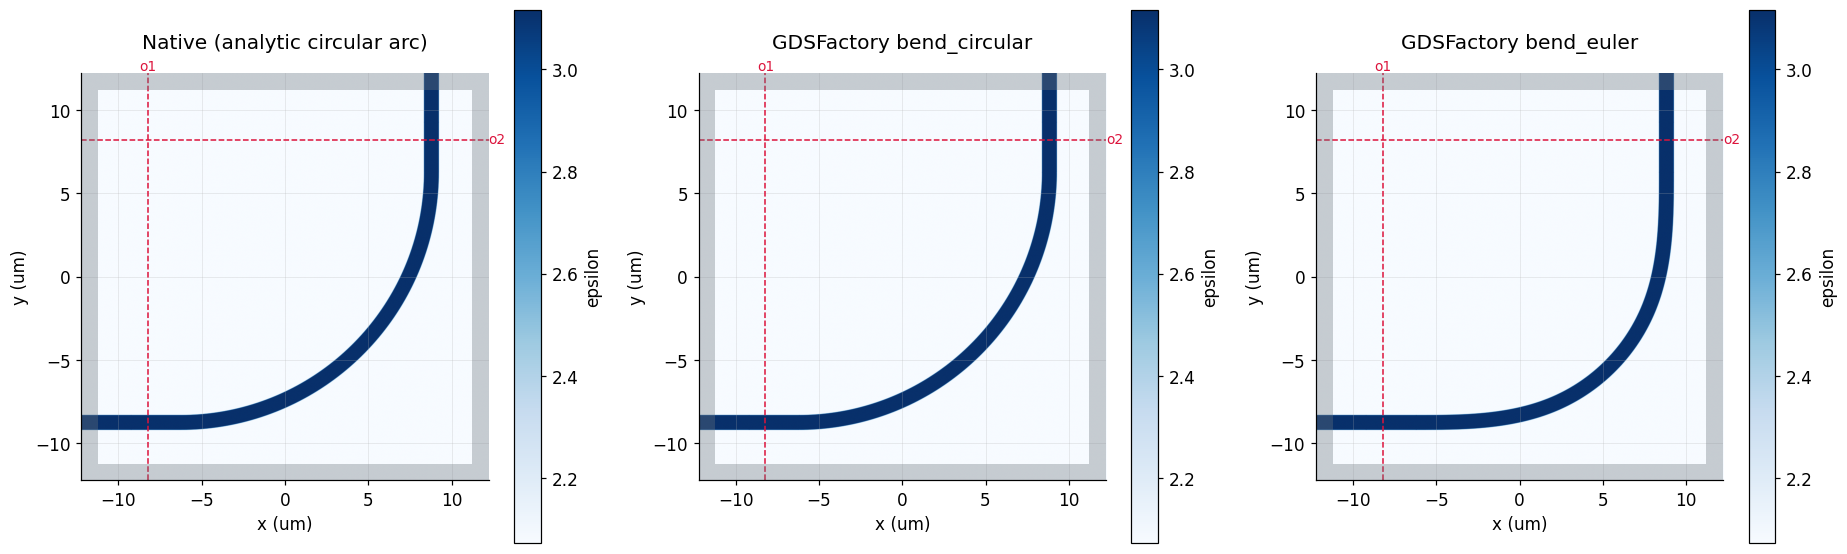

max |native - gds_circular| eps difference: 0.142
max |native - gds_euler|    eps difference: 1.042


In [4]:
# Three permittivity maps (no FDTD timestepping). Circular-vs-native should differ only
# at boundary pixels; Euler-vs-native should differ substantially (another shape).
def ports_for(p):
    p1c, p1s, p2c, p2s = bend._port_planes(p)
    return [(p1c.x, p1c.y, "o1", "v"), (p2c.x, p2c.y, "o2", "h")]

perm_native = bend.get_permittivity_map(params, use_native_geometry=True)
perm_gds_circular = bend.get_permittivity_map({**params, "bend_type": "circular"})
perm_gds_euler = bend.get_permittivity_map({**params, "bend_type": "euler"})

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, perm, title in [(axes[0], perm_native, "Native (analytic circular arc)"),
                        (axes[1], perm_gds_circular, "GDSFactory bend_circular"),
                        (axes[2], perm_gds_euler, "GDSFactory bend_euler")]:
    viz.plot_permittivity(perm.eps, perm.extent_um, ax=ax, ports=ports_for(params), pml_um=params["dpml_um"])
    ax.set_title(title, pad=16)
fig.tight_layout()
plt.show()

print(f"max |native - gds_circular| eps difference: {np.abs(perm_native.eps - perm_gds_circular.eps).max():.3f}")
print(f"max |native - gds_euler|    eps difference: {np.abs(perm_native.eps - perm_gds_euler.eps).max():.3f}")

> **STOP -- inspect all three permittivity maps before running any FDTD.**
>
> Check: the 0.9 µm core is fully clad in every panel; the two circular panels look the
> same; the `o1`/`o2` port lines sit on the straight arms, clear of the curve, with PML
> clearance beyond them.

## 4. 2D Meep FDTD simulation

### 4.1-4.2 Baseline runs (representative radius, both bend types)

Two independent runs per bend type (excite `o1`, then `o2`) measure the full 2×2
S-matrix. At 15 µm each bend type takes roughly 15--20 minutes.

In [5]:
# Full two-port characterization of both bend types at the representative radius.
results = {}
for bend_type in ["circular", "euler"]:
    results[bend_type] = bend.simulate_baseline({**params, "bend_type": bend_type})
    r = results[bend_type]
    print(f"{bend_type}: {len(r.wavelengths_um)} wavelength points, "
          f"{r.wavelengths_um.min():.4f}-{r.wavelengths_um.max():.4f} um")

circular: 21 wavelength points, 1.3017-1.4020 um


euler: 21 wavelength points, 1.3017-1.4020 um


### 4.3 Electromagnetic field visualization

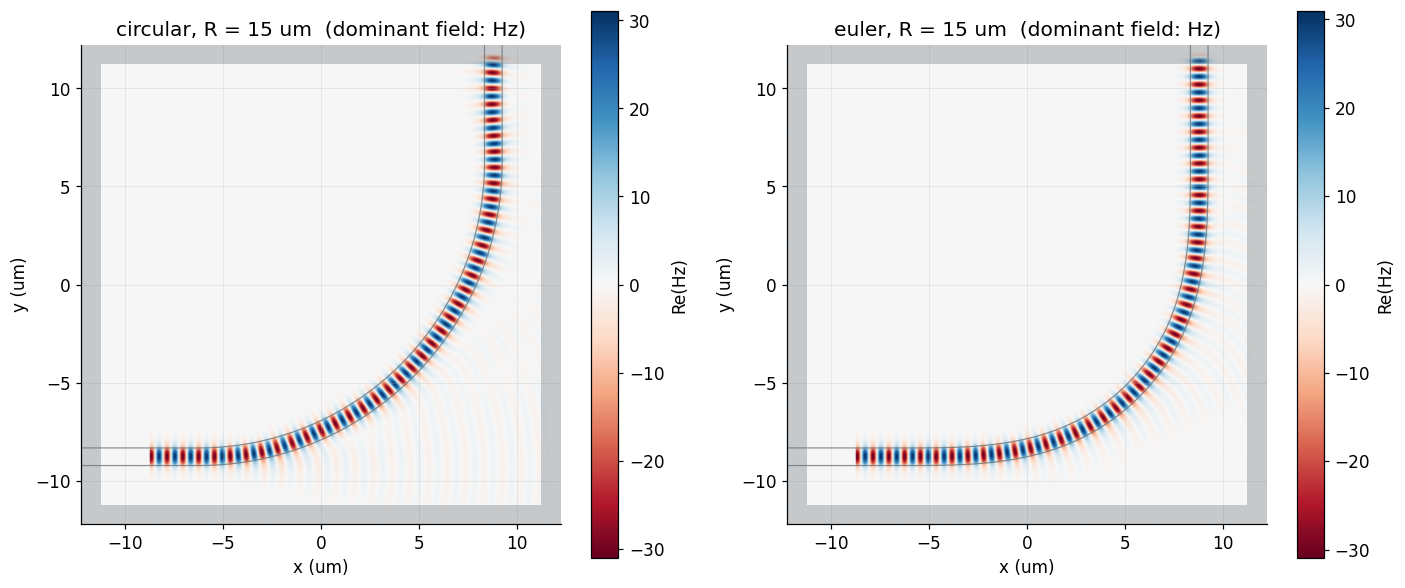

In [6]:
# Dominant field component of each o1-launch run.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, bend_type in zip(axes, ["circular", "euler"]):
    fs = results[bend_type].field_snapshot
    viz.plot_field(fs.field, fs.eps, fs.extent_um, component=fs.component, ax=ax, pml_um=params["dpml_um"])
    ax.set_title(f"{bend_type}, R = {params['radius_um']:g} um  (dominant field: {fs.component})")
fig.tight_layout()
plt.show()

> **STOP -- inspect the electromagnetic field before continuing.**
>
> Check: the field follows the curve from the horizontal to the vertical arm, and any
> radiation leaves from the outer side of the turn. At 15 µm the bend still loses a few
> percent, so faint radiation outside the arc is expected.

### 4.4 S-parameters

circular: |S11|^2=4.17e-06  |S21|^2=0.9591  insertion loss=0.181 dB  (at 1.3500 um)
euler: |S11|^2=5.97e-06  |S21|^2=0.9864  insertion loss=0.060 dB  (at 1.3500 um)


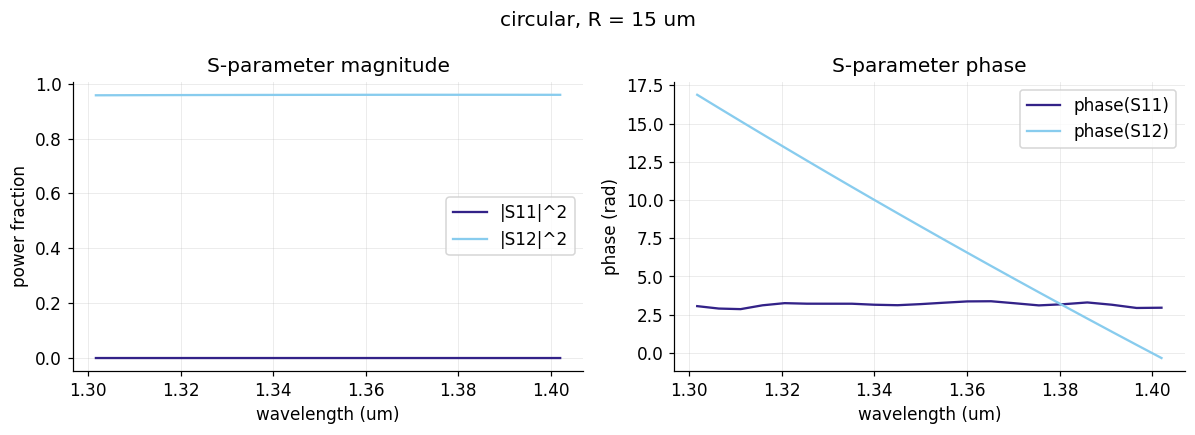

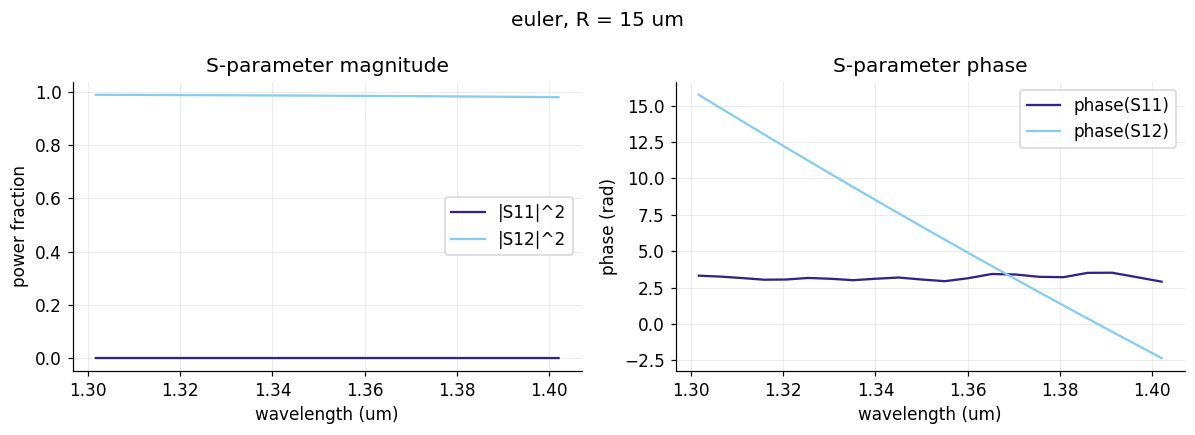

SAX SDict keys (circular): [('o1', 'o1'), ('o1', 'o2'), ('o2', 'o1'), ('o2', 'o2')]


In [7]:
# Mid-band S11/S21 and insertion loss for both bend types, plus the spectra.
for bend_type in ["circular", "euler"]:
    r = results[bend_type]
    i_mid = len(r.wavelengths_um) // 2
    s11, s21 = r.s_matrix["11"][i_mid], r.s_matrix["21"][i_mid]
    print(f"{bend_type}: |S11|^2={np.abs(s11)**2:.2e}  |S21|^2={np.abs(s21)**2:.4f}  "
          f"insertion loss={-10*np.log10(np.abs(s21)**2):.3f} dB  (at {r.wavelengths_um[i_mid]:.4f} um)")

for bend_type in ["circular", "euler"]:
    f = viz.plot_sparams(results[bend_type].wavelengths_um, results[bend_type].s_matrix, pairs=("11", "12"))
    f.suptitle(f"{bend_type}, R = {params['radius_um']:g} um")
    f.tight_layout()
plt.show()
sdict = sparams.to_sdict(results["circular"].s_matrix, results["circular"].port_names)
print("SAX SDict keys (circular):", list(sdict.keys()))

### 4.2b Radius sweep, both bend types

**The baselines above have been inspected -- only now do we sweep.** The radii run from
5 µm, where a circular bend loses about 3 dB, to 30 µm, where the Euler bend is at
0.001 dB and the circular one at 0.04 dB. That is the same span in *loss* that the Si track's 1.0--3.0 µm sweep
covers. The steps widen with radius because the loss changes on a log scale.

The sweep tolerances follow the Si track's, except `max_loss_fraction` = 0.7, which
admits the 4.9 dB (68 % of the power) of the 5 µm Euler bend. The FDTD runs were made headless with this
exact call, and `reuse_existing=True` reloads them (same geometry, resolution and
tolerances).

In [8]:
# 9 radii x 2 bend types; one artifact per point in sin/data/sparams/sin_bend/sweep.
RADIUS_SWEEP_UM = [5.0, 6.0, 8.0, 10.0, 12.0, 15.0, 20.0, 25.0, 30.0]
BEND_TYPES = ["circular", "euler"]
SWEEP_CHECK_KWARGS = {"energy_tol": 0.15, "reciprocity_tol": 0.15,
                      "passivity_tol": 0.05, "max_loss_fraction": 0.7}

bend_rows = sweep.grid_sweep(
    simulate_fn=bend.simulate_baseline,
    base_params=params,
    param_grid={"radius_um": RADIUS_SWEEP_UM, "bend_type": BEND_TYPES},
    artifact_dir="../data/sparams/sin_bend/sweep",
    component_name="sin_bend",
    check_kwargs=SWEEP_CHECK_KWARGS,
    reuse_existing=True,
)
n_passed = sum(row["validation_passed"] for row in bend_rows)
print(f"radius x bend_type sweep: {n_passed}/{len(bend_rows)} points within the sweep tolerance")
sweep.save_manifest(bend_rows, "../data/sparams/sin_bend/sweep/manifest.csv")

[1/18  5%] running sin_bend (radius_um=5.0, bend_type=circular) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[2/18  11%] running sin_bend (radius_um=5.0, bend_type=euler) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[3/18  16%] running sin_bend (radius_um=6.0, bend_type=circular) ...


...

[17/18  94%] running sin_bend (radius_um=30.0, bend_type=circular) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[18/18  100%] running sin_bend (radius_um=30.0, bend_type=euler) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


radius x bend_type sweep: 18/18 points within the sweep tolerance


Reading sweep results at wavelength = 1.3500 um


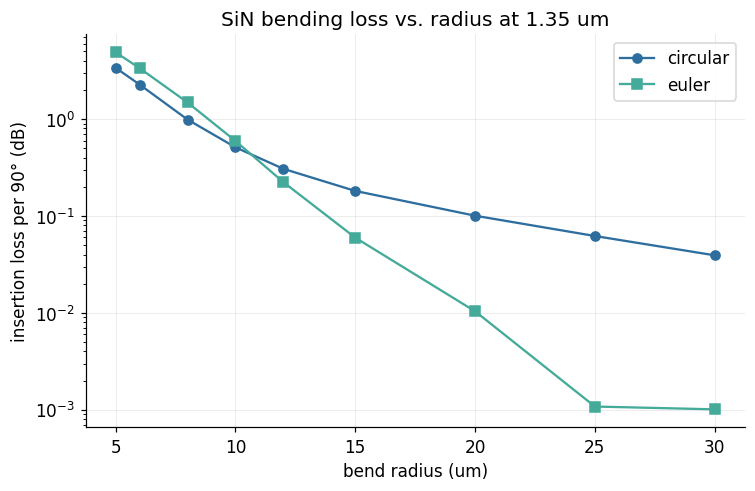

circular: 5: 3.3820, 6: 2.2711, 8: 0.9883, 10: 0.5112, 12: 0.3064, 15: 0.1813, 20: 0.1006, 25: 0.0621, 30: 0.0392
euler: 5: 4.8885, 6: 3.3516, 8: 1.4841, 10: 0.5947, 12: 0.2234, 15: 0.0597, 20: 0.0104, 25: 0.0011, 30: 0.0010


In [9]:
# Insertion loss and S21 at the band center, per bend type and radius.
i_mid = len(results["circular"].wavelengths_um) // 2
wl0 = float(results["circular"].wavelengths_um[i_mid])
print(f"Reading sweep results at wavelength = {wl0:.4f} um")

def load_sweep(stem_fmt, radii):
    s21 = {}
    for bend_type in BEND_TYPES:
        s21[bend_type] = np.array([sparams.load_artifact(stem_fmt.format(r=r, t=bend_type)).s_matrix["21"][i_mid]
                                   for r in radii])
    return s21

s21_by_type = load_sweep("../data/sparams/sin_bend/sweep/sin_bend_radius{r}_bend_type{t}", RADIUS_SWEEP_UM)
loss_db_by_type = {t: -10 * np.log10(np.abs(s) ** 2) for t, s in s21_by_type.items()}

fig, ax = plt.subplots(figsize=(7, 4.6))
for bend_type, color, marker in zip(BEND_TYPES, [style.COLOR_STEEL, style.COLOR_TEAL], ["o-", "s-"]):
    ax.semilogy(RADIUS_SWEEP_UM, loss_db_by_type[bend_type], marker, color=color, label=bend_type)
ax.set_xlabel("bend radius (um)")
ax.set_ylabel("insertion loss per 90° (dB)")
ax.set_title("SiN bending loss vs. radius at 1.35 um")
ax.legend()
fig.tight_layout()
plt.show()

for bend_type in BEND_TYPES:
    print(f"{bend_type}: " + ", ".join(f"{r:g}: {l:.4f}" for r, l in zip(RADIUS_SWEEP_UM, loss_db_by_type[bend_type])))

**Reading.** Both bend types lose about as much as they transmit at R = 5 µm: 3.4 dB
(circular) and 4.9 dB (Euler). The loss then falls steeply.

- **Euler.** It falls by more than three decades, to about 0.001 dB at 25–30 µm. Its
  smooth curvature entry removes the straight-to-arc junction, so only radiation is left,
  and radiation falls roughly exponentially with R.
- **Circular.** Below about 12 µm it follows the Euler curve. It then flattens: 0.18 dB at
  15 µm, 0.10 dB at 20 µm, 0.039 dB at 30 µm. Above about 15 µm the loss is set by the
  abrupt curvature step at the two junctions (mode mismatch), which falls only slowly with R.
- **Crossover.** Up to R = 10 µm the Euler bend is *worse*: 0.59 against 0.51 dB. Its
  peak curvature in the same footprint is tighter than 1/R (Section 4.2b). From 12 µm on it
  is better. This is the same ordering Pita Ruiz et al. measured at R = 6 µm (Euler 3.44 dB
  against circular 2.86 dB).

## 5. SAX model fitting

The same model form as the Si track (`models/bend.py`), fitted per bend type at the band
center.

- **Loss.** $\mathrm{floor} + A\,e^{-R/R_0}$. The loss spans three decades over the sweep,
  so each point is weighted by its relative uncertainty (σ ∝ loss + 0.002 dB) rather than
  equally. Otherwise the fit would follow only the 5--8 µm points.
- **Phase, with the propagation phase taken out before unwrapping.** Between two sweep
  radii the phase of $S_{21}$ advances by about $\beta\,L'(R)\,\Delta R$, e.g. 31 rad for
  $\Delta R$ = 5 µm. That is far more than π, so `np.unwrap` of the raw phase would return
  an aliased slope that is right only at the sampled radii.
  - The fit therefore subtracts the straight-waveguide phase $\beta_0\,L_\mathrm{path}(R)$
    first, with $\beta_0 = 2\pi n_\mathrm{eff}/\lambda$ from `sin_waveguide.yaml`.
  - $L_\mathrm{path}$ is gdsfactory's own centre-line length for each bend type:
    $\pi R/2 = 1.571\,R$ for the circular arc, but $1.664\,R$ for `bend_euler`. The Euler
    path is longer because of its clothoid entry and exit.
  - Subtracting only $\pi R/2$ for the Euler bend would leave $\beta_0\times0.093 \approx$
    0.73 rad/µm, i.e. 3.6 rad per 5 µm step, which is still more than π and still aliased.
    The Si track's 0.25 µm steps leave only 0.27 rad, which is why it does not show this.
  - It unwraps and fits the slowly varying remainder, then adds $\beta_0 L_\mathrm{path}/R$
    back to the slope.
  - The stored `phase_slope` is therefore the true $d\phi/dR$.

centre-line length / R: {'circular': 1.5708, 'euler': 1.6637}


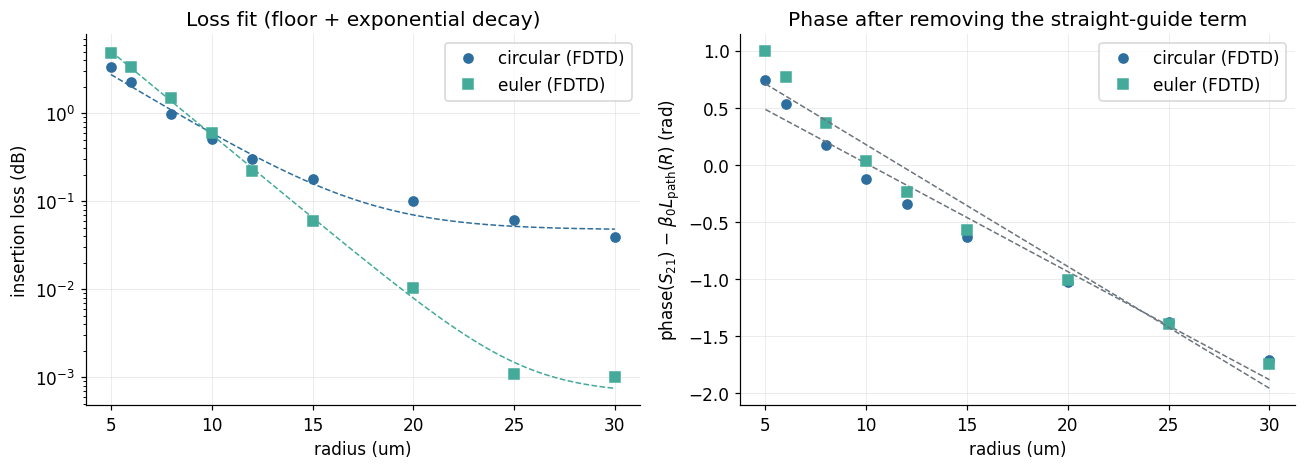

circular: floor 4.74e-02 dB, A 13.4 dB, R0 3.134 um, dphi/dR 12.228 rad/um (beta0*L/R = 12.322), max |phase residual| 0.254 rad
euler: floor 6.57e-04 dB, A 44.8 dB, R0 2.293 um, dphi/dR 12.944 rad/um (beta0*L/R = 13.051), max |phase residual| 0.285 rad


In [10]:
# Loss: relative-error-weighted exponential-plus-floor fit. Phase: remove the straight-
# guide propagation phase over each bend type's own centre-line length (gdsfactory's
# info["length"], which scales exactly with R), unwrap the slow remainder, fit it
# linearly, and add the removed slope back.
with open("../data/design_points/sin_waveguide.yaml") as f:
    n_eff_straight = yaml.safe_load(f)["fitted_model"]["n_eff"]
beta0 = 2 * np.pi * n_eff_straight / wl0
_bend_fns = {"circular": gf.components.bend_circular, "euler": gf.components.bend_euler}
path_per_radius = {bt: fn(radius=10.0, angle=90, allow_min_radius_violation=True).info["length"] / 10.0
                   for bt, fn in _bend_fns.items()}
print("centre-line length / R:", {bt: round(v, 4) for bt, v in path_per_radius.items()})

def _loss_model(r, floor, amplitude, decay_um):
    return floor + amplitude * np.exp(-r / decay_um)

radii = np.array(RADIUS_SWEEP_UM)
fitted_model, phase_residual_by_type = {}, {}
fig, (ax_loss, ax_phase) = plt.subplots(1, 2, figsize=(12, 4.4))
for bend_type, color, marker in zip(BEND_TYPES, [style.COLOR_STEEL, style.COLOR_TEAL], ["o", "s"]):
    loss_db = loss_db_by_type[bend_type]
    p0 = [max(loss_db.min(), 0.0), loss_db.max() * np.exp(radii.min() / 4.0), 4.0]
    (floor, amplitude, decay_um), _ = curve_fit(
        _loss_model, radii, loss_db, p0=p0, sigma=loss_db + 0.002,
        bounds=([0, 0, 1e-3], [np.inf, np.inf, np.inf]), maxfev=20000,
    )
    slow = np.unwrap(np.angle(s21_by_type[bend_type] * np.exp(-1j * beta0 * path_per_radius[bend_type] * radii)))
    slow_fit = np.polyfit(radii, slow, 1)
    phase_residual_by_type[bend_type] = slow - np.polyval(slow_fit, radii)
    fitted_model[bend_type] = {
        "loss_db_floor": float(floor), "loss_db_amplitude": float(amplitude),
        "loss_db_decay_um": float(decay_um),
        "phase_slope": float(slow_fit[0] + beta0 * path_per_radius[bend_type]), "phase_intercept": float(slow_fit[1]),
    }
    r_fine = np.linspace(radii.min(), radii.max(), 200)
    ax_loss.semilogy(radii, loss_db, marker, color=color, label=f"{bend_type} (FDTD)")
    ax_loss.semilogy(r_fine, _loss_model(r_fine, floor, amplitude, decay_um), "--", color=color, lw=1)
    ax_phase.plot(radii, slow, marker, color=color, label=f"{bend_type} (FDTD)")
    ax_phase.plot(radii, np.polyval(slow_fit, radii), "--", color=style.COLOR_REFERENCE, lw=1)

ax_loss.set_xlabel("radius (um)"); ax_loss.set_ylabel("insertion loss (dB)")
ax_loss.set_title("Loss fit (floor + exponential decay)"); ax_loss.legend()
ax_phase.set_xlabel("radius (um)"); ax_phase.set_ylabel(r"phase($S_{21}$) $-\ \beta_0 L_\mathrm{path}(R)$ (rad)")
ax_phase.set_title("Phase after removing the straight-guide term"); ax_phase.legend()
fig.tight_layout()
plt.show()

for bend_type in BEND_TYPES:
    fm = fitted_model[bend_type]
    print(f"{bend_type}: floor {fm['loss_db_floor']:.2e} dB, A {fm['loss_db_amplitude']:.3g} dB, "
          f"R0 {fm['loss_db_decay_um']:.3f} um, dphi/dR {fm['phase_slope']:.3f} rad/um "
          f"(beta0*L/R = {beta0*path_per_radius[bend_type]:.3f}), max |phase residual| "
          f"{np.abs(phase_residual_by_type[bend_type]).max():.3f} rad")

**Reading.**
- **Euler.** The fit follows all nine points over 3.5 decades: R0 = 2.29 µm, floor
  0.0007 dB. The floor is at the level of the measurement noise and has no physical
  meaning.
- **Circular.** R0 = 3.13 µm, and the fitted floor is 0.047 dB. That floor stands in for
  the junction loss, which in reality keeps falling slowly with R (0.039 dB is measured at
  30 µm). The fit is therefore about 30 % low at 20 µm and about 20 % high at 30 µm.
  Treat circular-bend values from the SAX model above 20 µm as ±30 %.
- **Phase.** After the straight-guide term is removed, the remainder is smooth (residual
  ≤ 0.29 rad), with no sawtooth. The slopes are 12.23 (circular) and 12.94 (Euler) rad/µm.
  Both are about 0.1 rad/µm (0.8 %) below $\beta_0 L_\mathrm{path}/R$ (12.32 / 13.05).
  The bent mode's propagation constant differs slightly from the straight guide's, and
  the linear fit absorbs that difference.

> **STOP -- inspect the fits before saving.**
>
> The dashed loss curves should follow the points over the whole three decades. The
> phase remainder should be a smooth, slowly varying line, not a sawtooth. A sawtooth
> would mean the propagation term was not removed correctly.

## 6. Sanity checks

The shared validator on both representative-radius baselines, with the Si bend's
baseline tolerances.

In [11]:
# Same tolerances as the Si track's bend baseline (energy budget, reciprocity, passivity).
ENERGY_TOL, RECIPROCITY_TOL, PASSIVITY_TOL, MAX_LOSS_FRACTION = 0.08, 0.10, 0.02, 0.15
validations = {}
for bend_type in BEND_TYPES:
    v = checks.run_all_checks(results[bend_type].s_matrix, energy_tol=ENERGY_TOL,
                              reciprocity_tol=RECIPROCITY_TOL, passivity_tol=PASSIVITY_TOL,
                              max_loss_fraction=MAX_LOSS_FRACTION)
    validations[bend_type] = v
    print(f"--- {bend_type} ---")
    print(json.dumps(v, indent=2))
    assert v["passed"], f"{bend_type} baseline failed sanity checks -- do not save or use this result."
print("\nBoth baselines validated.")

--- circular ---
{
  "energy_conservation": {
    "max_deviation_port1": 0.0,
    "max_deviation_port2": 0.0,
    "max_deviation": 0.0,
    "max_loss_fraction_allowed": 0.15,
    "tolerance": 0.08,
    "passed": true
  },
  "reciprocity": {
    "max_diff_s12_s21": 1.6459846355226393e-06,
    "max_diff_s11_s22": 3.481783509168859e-05,
    "max_diff": 3.481783509168859e-05,
    "tolerance": 0.1,
    "passed": true
  },
  "passivity": {
    "max_magnitude": 0.979481199968669,
    "tolerance": 0.02,
    "passed": true
  },
  "passed": true
}
--- euler ---
{
  "energy_conservation": {
    "max_deviation_port1": 0.0,
    "max_deviation_port2": 0.0,
    "max_deviation": 0.0,
    "max_loss_fraction_allowed": 0.15,
    "tolerance": 0.08,
    "passed": true
  },
  "reciprocity": {
    "max_diff_s12_s21": 2.619970861462746e-06,
    "max_diff_s11_s22": 4.721873500497922e-05,
    "max_diff": 4.721873500497922e-05,
    "tolerance": 0.1,
    "passed": true
  },
  "passivity": {
    "max_magnitude": 0

## 7. Save artifacts and design point

One artifact per bend type and one design point for both, in `sin/data/`.

**Design radius.** The design radius is the smallest swept radius at which the
better bend type loses at most 0.05 dB per 90°. The Si track keeps 2.0 µm as its
representative radius; Section 9 compares the two platforms at equal loss, not at their
representative radii.

In [12]:
# Artifacts for the two baselines.
artifact_stems = {}
for bend_type in BEND_TYPES:
    r = results[bend_type]
    artifact_stem = f"../data/sparams/sin_bend/baseline/sin_bend_baseline_{bend_type}"
    metadata = {
        "component": "sin_bend",
        "geometry_params": {k: r.sim_params[k] for k in ["radius_um", "arm_length_um", "wg_width_um", "sin_thickness_um"]}
                           | {"bend_type": bend_type},
        "material_params": {"core_index": r.sim_params["core_index"], "clad_index": r.sim_params["clad_index"]},
        "polarization": f"TE ({r.field_snapshot.component} out-of-plane, confirmed dominant -- see Section 4.3)",
        "geometry_source": "gdsfactory (build_gf_component -> build_geometry_from_gds)",
        "meep_resolution": r.sim_params["resolution"],
        "simulation_params": {k: r.sim_params[k] for k in ["wl_min_um", "wl_max_um", "n_freq", "dpml_um",
                                                           "margin_um", "port_offset_um", "source_offset_um"]},
        "meep_version": r.sim_params["meep_version"],
        "python_version": r.sim_params["python_version"],
        "creation_date": r.sim_params["creation_date"],
        "validation": validations[bend_type],
    }
    sparams.save_artifact(artifact_stem, r.wavelengths_um, r.freqs, r.s_matrix, r.port_names, metadata)
    artifact_stems[bend_type] = "sin/data/" + artifact_stem.replace("../data/", "")
    print(f"Saved artifact: {artifact_stem}.npz / .json")

Saved artifact: ../data/sparams/sin_bend/baseline/sin_bend_baseline_circular.npz / .json
Saved artifact: ../data/sparams/sin_bend/baseline/sin_bend_baseline_euler.npz / .json


In [13]:
# Design radius (smallest swept radius where the lower-loss bend type is <= 0.05 dB) and
# the design point read by models/sin_bend.py.
DESIGN_LOSS_DB = 0.05
best_loss = np.minimum(loss_db_by_type["circular"], loss_db_by_type["euler"])
i_design = int(np.argmax(best_loss <= DESIGN_LOSS_DB))
assert best_loss[i_design] <= DESIGN_LOSS_DB
design_radius = RADIUS_SWEEP_UM[i_design]
design_type = "circular" if loss_db_by_type["circular"][i_design] <= loss_db_by_type["euler"][i_design] else "euler"
print(f"design radius {design_radius:g} um, {design_type}: {best_loss[i_design]:.4f} dB per 90 deg")

design_point_path = "../data/design_points/sin_bend.yaml"
design_points.save_design_point(design_point_path, {
    "component": "sin_bend",
    "parameters": {
        "radius_um": design_radius,
        "arm_length_um": params["arm_length_um"],
        "wg_width_um": params["wg_width_um"],
        "sin_thickness_um": params["sin_thickness_um"],
        "core_index": params["core_index"],
        "clad_index": params["clad_index"],
        "bend_type": design_type,
        "design_loss_db": DESIGN_LOSS_DB,
    },
    "source_artifacts": artifact_stems,
    "fitted_model": fitted_model,
    "fit_range_um": [min(RADIUS_SWEEP_UM), max(RADIUS_SWEEP_UM)],
    "provenance": {
        "method": "baseline_plus_radius_sweep_fit",
        "date": results["circular"].sim_params["creation_date"],
        "meep_version": results["circular"].sim_params["meep_version"],
    },
    "validation": validations,
    "rationale": (
        f"Baselines validated at radius_um={REPRESENTATIVE_RADIUS_UM:g} for both bend types. Loss "
        "(relative-error weighted exponential + floor) and phase (straight-guide term removed "
        "before unwrapping, so phase_slope is the true dphi/dR) fit per bend type from a "
        "5-30 um radius sweep at resolution 40. Design radius: smallest swept radius with "
        f"<= {DESIGN_LOSS_DB} dB per 90 deg for the better bend type."
    ),
})
print(f"Saved design point: {design_point_path}")

design radius 20 um, euler: 0.0104 dB per 90 deg
Saved design point: ../data/design_points/sin_bend.yaml


## 8. The bend SAX model

`models/sin_bend.py` evaluates the design point above with the same code as the Si
track's `models/bend.py` (`bend_from_record`). It never imports meep.

In [14]:
with open("../../src/pic_toolkit/models/sin_bend.py") as f:
    print(f.read())

"""SAX-compatible model for the SiN-track 90-degree bend.

Same model form as models/bend.py (loss_dB = floor + amplitude*exp(-R/decay),
phase linear in R, one fit per bend_type at the band center), read from the SiN
design point that sin/notebooks/02_sin_bent_waveguide.ipynb saves. Never
imports meep. The fit covers the SiN radius sweep stored in the design point;
do not extrapolate far outside it.
"""

from __future__ import annotations

from pathlib import Path

from .. import design_points
from .bend import bend_from_record

_REPO_ROOT = Path(__file__).resolve().parents[3]
_DESIGN_POINT_PATH = _REPO_ROOT / "sin" / "data" / "design_points" / "sin_bend.yaml"


def sin_bend(wl=1.35, radius_um: float | None = None, bend_type: str = "circular"):
    """SAX model function: wavelength (um), bend radius (um, defaults to the
    design radius), bend_type ("circular" or "euler") -> SDict. See
    models.bend.bend."""
    design_point = design_points.load_design_point(_DESIGN_POINT_PATH)
    

## 9. SiN vs. Si

### 9.0 What the SiN bend is compared against

A ratio of bend radii is only as good as the two models behind it. Both platforms are
therefore modelled with **the same calibration**: the 2D core index is chosen so that the
2D lateral TE0 mode has the effective index of the real cross-section (notebook 01 §1.1,
`slab_modes.core_index_for_neff`).

| | real cross-section n_eff (MPB) | 2D core index | 2D n_eff |
|---|---|---|---|
| SiN 900 × 400 nm (this track) | 1.6753 | 1.7650 | 1.6753 |
| Si 500 × 220 nm (**Si reference**) | 2.671 | 2.944 | 2.671 |
| Si track (`notebooks/`, simplified) | -- | 2.7 | 2.418 |

The Si track's simplified core index of 2.7 gives a mode index 0.25 below that of a real
500 × 220 nm Si strip. Its lateral confinement is therefore much weaker, and its bends
lose several times more than a real Si bend (§9.1). The Si track is still shown for
reference below, but **every ratio in this section uses the Si reference**.

The Si reference was swept with the same bend builder, resolution (40 px/µm) and
tolerances as the SiN sweep. Its artifacts are in `sin/data/sparams/si_ref_bend/`.

### 9.1 Model validation against published 3D results

Before comparing the two platforms, the calibrated 2D model is run at the geometry and
wavelength of two published studies, and compared with their numbers. Each benchmark is
calibrated exactly like the main runs: MPB cross-section n_eff, then
`core_index_for_neff`. Each also uses the publication's own material indices.

- **Si:** Bahadori et al., *J. Lightwave Technol.* 37, 3044 (2019).
  - 3D FDTD of circular 90° bends, 400 × 220 nm Si in SiO₂, TE₀, 1.55 µm.
  - The paper fits its FDTD results as radiation $\alpha_r = 181.98\,R^{-2.49}$ dB/cm
    along the arc, plus a mode-mismatch loss $L_m = 0.1315\,R^{-2.37}$ dB at each of the
    two junctions.
  - Here: Si 3.476, SiO₂ 1.444, MPB n_eff 2.2265, 2D core 2.754.
- **SiN:** Pita Ruiz, Dalvand and Ménard, *J. Lightwave Technol.* 43, 5804 (2025).
  - 850 × 400 nm SiN in SiO₂, TE, C band.
  - Circular and Euler bends in a 6 × 6 µm² footprint: 2.88 / 3.46 dB simulated, and
    2.86 / 3.44 dB measured.
  - Here: SiN 1.997, SiO₂ 1.441 (the group's values), MPB n_eff 1.6097, 2D core 1.7187.

Air-clad measurements such as Vlasov and McNab, *Opt. Express* 12, 1622 (2004), are
**not** used. Their 445 × 220 nm strip sits between two 2 µm air trenches, with no oxide
on top, so it is a different (and more strongly confined) structure.

In [15]:
# Benchmarks: calibrated 2D FDTD at the publications' geometry/wavelength (1.55 um band
# centre), read from their artifacts, against the published numbers.
def loss_at_centre(stem):
    a = sparams.load_artifact(stem)
    i = len(a.wavelengths_um) // 2
    return float(-10 * np.log10(abs(a.s_matrix["21"][i]) ** 2)), float(a.wavelengths_um[i]), a.metadata["validation"]["passed"]

def bahadori_loss_db(R):
    # Bahadori et al. 2019, Eqs. (3)-(5) with their FDTD fit: arc radiation + 2 junctions.
    return 181.98 * R ** -2.49 * (np.pi * R / 2) * 1e-4 + 2 * 0.1315 * R ** -2.37

BAHADORI_RADII = [1.0, 1.5, 2.0, 3.0, 5.0]
bench_si = {R: loss_at_centre(f"../data/sparams/benchmark/si_400x220_c_band/si_bahadori_bend_radius{R}_bend_typecircular")
            for R in BAHADORI_RADII}
print("Si 400x220 nm, circular, C band            this model   Bahadori 2019 fit   ratio")
for R, (l, wl_c, ok) in bench_si.items():
    print(f"  R = {R:3.1f} um  (at {wl_c:.3f} um, valid={ok})       {l:8.4f} dB   {bahadori_loss_db(R):8.4f} dB   {l / bahadori_loss_db(R):5.2f}")
print("  (Bahadori's directly simulated circular bend at R = 5 um: 0.0125 dB)")

PITA_RUIZ = {"circular": (2.88, 2.86), "euler": (3.46, 3.44)}  # (3D sim, measured), dB
print()
print("SiN 850x400 nm, R = 6 um, C band   this model   Pita Ruiz 2025 sim / meas")
bench_sin = {}
for bt, (sim, meas) in PITA_RUIZ.items():
    l, wl_c, ok = loss_at_centre(f"../data/sparams/benchmark/sin_850x400_c_band/sin_pitaruiz_bend_radius6.0_bend_type{bt}")
    bench_sin[bt] = l
    print(f"  {bt:8s} (valid={ok})          {l:6.2f} dB    {sim:.2f} / {meas:.2f} dB")

print()
print("Si reference grid check (circular, 1.35 um): resolution 40 vs 60 px/um")
for R in (1.0, 2.0):
    l40 = loss_at_centre(f"../data/sparams/si_ref_bend/sweep/si_ref_bend_radius{R}_bend_typecircular")[0]
    l60 = loss_at_centre(f"../data/sparams/si_ref_bend/convergence/si_ref_bend_res60_radius{R}_bend_typecircular")[0]
    print(f"  R = {R:g} um: {l40:.4f} dB (40)  {l60:.4f} dB (60)  change {100 * (l60 - l40) / l60:+.1f} %")

Si 400x220 nm, circular, C band            this model   Bahadori 2019 fit   ratio
  R = 1.0 um  (at 1.550 um, valid=True)         1.3790 dB     0.2916 dB    4.73
  R = 1.5 um  (at 1.550 um, valid=True)         0.4272 dB     0.1162 dB    3.68
  R = 2.0 um  (at 1.550 um, valid=True)         0.1923 dB     0.0611 dB    3.15
  R = 3.0 um  (at 1.550 um, valid=True)         0.0645 dB     0.0250 dB    2.58
  R = 5.0 um  (at 1.550 um, valid=True)         0.0230 dB     0.0084 dB    2.74
  (Bahadori's directly simulated circular bend at R = 5 um: 0.0125 dB)

SiN 850x400 nm, R = 6 um, C band   this model   Pita Ruiz 2025 sim / meas
  circular (valid=True)            5.22 dB    2.88 / 2.86 dB
  euler    (valid=True)            6.82 dB    3.46 / 3.44 dB

Si reference grid check (circular, 1.35 um): resolution 40 vs 60 px/um
  R = 1 um: 0.3760 dB (40)  0.3875 dB (60)  change +3.0 %
  R = 2 um: 0.0637 dB (40)  0.0593 dB (60)  change -7.5 %


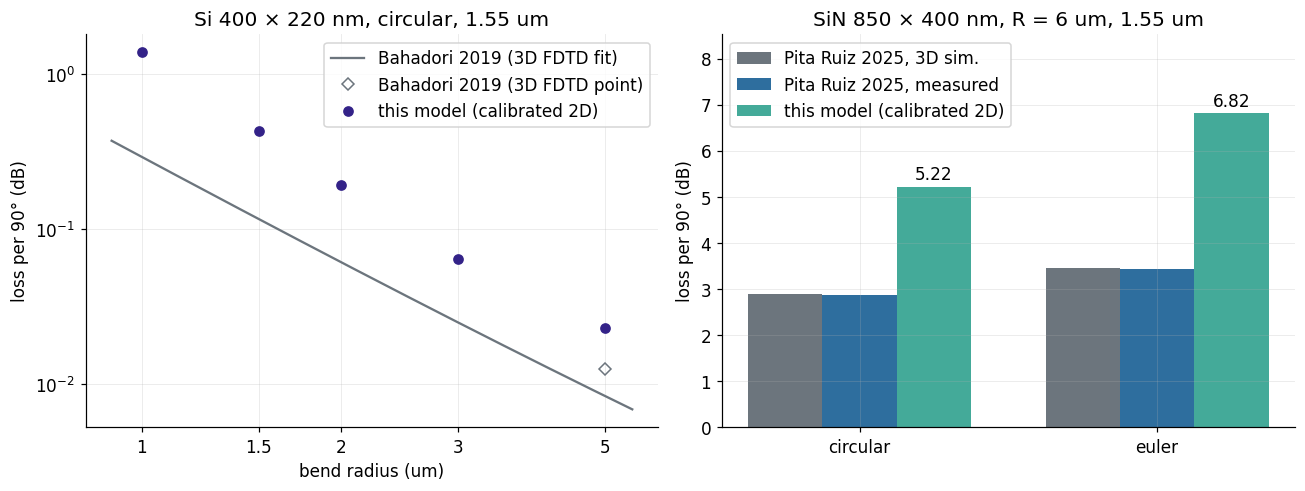

In [16]:
# Benchmark figure: Si (left) against Bahadori's fitted 3D FDTD curve, SiN (right)
# against Pita Ruiz's simulated and measured 6 um bends.
fig, (ax_si, ax_sin) = plt.subplots(1, 2, figsize=(12, 4.6))
r_fine = np.linspace(0.9, 5.5, 200)
ax_si.loglog(r_fine, bahadori_loss_db(r_fine), "-", color=style.COLOR_REFERENCE, label="Bahadori 2019 (3D FDTD fit)")
ax_si.loglog([5.0], [0.0125], "D", color=style.COLOR_REFERENCE, mfc="none", label="Bahadori 2019 (3D FDTD point)")
ax_si.loglog(BAHADORI_RADII, [bench_si[R][0] for R in BAHADORI_RADII], "o", color=style.COLOR_INDIGO,
             label="this model (calibrated 2D)")
ax_si.set_xticks([1, 1.5, 2, 3, 5]); ax_si.set_xticklabels(["1", "1.5", "2", "3", "5"])
ax_si.minorticks_off()
ax_si.set_xlabel("bend radius (um)"); ax_si.set_ylabel("loss per 90° (dB)")
ax_si.set_title("Si 400 × 220 nm, circular, 1.55 um")
ax_si.legend()

x = np.arange(2)
ax_sin.bar(x - 0.25, [PITA_RUIZ[b][0] for b in BEND_TYPES], 0.25, color=style.COLOR_REFERENCE, label="Pita Ruiz 2025, 3D sim.")
ax_sin.bar(x, [PITA_RUIZ[b][1] for b in BEND_TYPES], 0.25, color=style.COLOR_STEEL, label="Pita Ruiz 2025, measured")
bars = ax_sin.bar(x + 0.25, [bench_sin[b] for b in BEND_TYPES], 0.25, color=style.COLOR_TEAL, label="this model (calibrated 2D)")
ax_sin.bar_label(bars, fmt="%.2f", padding=2)
ax_sin.set_xticks(x); ax_sin.set_xticklabels(BEND_TYPES)
ax_sin.set_ylabel("loss per 90° (dB)")
ax_sin.set_title("SiN 850 × 400 nm, R = 6 um, 1.55 um")
ax_sin.legend(loc="upper left")
ax_sin.set_ylim(0, 1.25 * max(bench_sin.values()))
fig.tight_layout()
plt.show()

**Reading.** The calibrated 2D model **overestimates** bend loss in both benchmarks, by a
similar factor.

- **Si 400 × 220 nm.**
  - It is 2.6–4.7× above Bahadori's fitted curve. The factor is largest at R = 1 µm, where
    their fit is dominated by the junction mismatch term.
  - Their own directly simulated point at R = 5 µm (0.0125 dB) lies above their fit.
    Against that point the factor is 1.8×.
  - The 2D curve has a similar slope. Over 1.5–5 µm it falls 18.6×; the fit falls
    13.8×.
- **SiN 850 × 400 nm, R = 6 µm.**
  - 5.2 dB (circular) and 6.8 dB (Euler), against 2.88 / 3.46 dB (3D simulation) and
    2.86 / 3.44 dB (measured): 1.8× and 2.0×.
  - The ordering (Euler worse in this footprint) is reproduced, with a ratio of 1.31
    against 1.20.
- **Grid.** On the Si reference, 40 vs 60 px/µm changes the loss by +3 % (R = 1 µm) and
  −7.5 % (R = 2 µm), far less than the benchmark factor. So the factor is a property of the
  2D model, not of the grid.

**What it means for the comparison.**
- Bend loss falls exponentially with R, so a factor of 2–3 in loss is a small shift in
  radius.
  - Si: this model reaches Bahadori's 0.061 dB at R = 2 µm only at about 3 µm.
  - SiN: near R = 6 µm the loss falls by a factor e^0.4 per µm, so the factor 1.8 costs
    about ln 1.8 / 0.4 ≈ 1.5 µm, i.e. 25 %.
- The absolute radii below are therefore **conservative**: roughly 1.5× (Si) and 1.25×
  (SiN) larger than a 3D solver would give.
- Because the overestimate is larger for Si, the SiN/Si radius ratio from this model is,
  if anything, slightly **high**. A 3D-corrected estimate is about 8 × 1.25 / 1.5 ≈ 7×.
- These corrections are read off two benchmarks at a different wavelength and width, so
  treat them as factor-level, not as a calibration.

### 9.2 Loss against radius at 1.35 µm

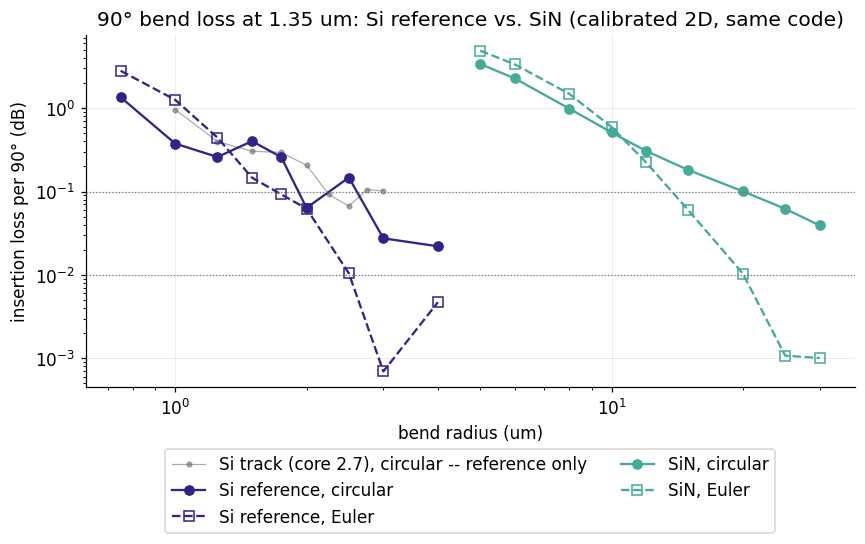

Si reference circular: 0.75: 1.3504, 1: 0.3760, 1.25: 0.2594, 1.5: 0.4016, 1.75: 0.2587, 2: 0.0637, 2.5: 0.1473, 3: 0.0275, 4: 0.0221
Si reference euler: 0.75: 2.8049, 1: 1.2572, 1.25: 0.4436, 1.5: 0.1467, 1.75: 0.0925, 2: 0.0625, 2.5: 0.0105, 3: 0.0007, 4: 0.0047


In [17]:
# Si reference sweep (calibrated 500 x 220 nm, same code and resolution) next to the SiN
# sweep; the Si track (simplified core 2.7) in grey for reference only.
SI_REF_RADII_UM = [0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0]
si_ref_loss = {t: -10 * np.log10(np.abs(s) ** 2) for t, s in
               load_sweep("../data/sparams/si_ref_bend/sweep/si_ref_bend_radius{r}_bend_type{t}", SI_REF_RADII_UM).items()}
SI_TRACK_RADII_UM = [round(1.0 + 0.25 * i, 2) for i in range(9)]
si_track_loss = {t: -10 * np.log10(np.abs(s) ** 2) for t, s in
                 load_sweep("../../si/data/sparams/bend/sweep/bend_radius{r}_bend_type{t}", SI_TRACK_RADII_UM).items()}

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.loglog(SI_TRACK_RADII_UM, si_track_loss["circular"], "o-", color=style.COLOR_REFERENCE, lw=0.8, ms=3, alpha=0.6,
          label="Si track (core 2.7), circular -- reference only")
for (label, rr, loss), color in zip(
        [("Si reference", SI_REF_RADII_UM, si_ref_loss), ("SiN", RADIUS_SWEEP_UM, loss_db_by_type)],
        [style.COLOR_INDIGO, style.COLOR_TEAL]):
    ax.loglog(rr, np.clip(loss["circular"], 1e-4, None), "o-", color=color, label=f"{label}, circular")
    ax.loglog(rr, np.clip(loss["euler"], 1e-4, None), "s--", color=color, mfc="none", label=f"{label}, Euler")
for level in (0.1, 0.01):
    ax.axhline(level, color=style.COLOR_REFERENCE, lw=0.8, ls=":")
ax.set_xlabel("bend radius (um)")
ax.set_ylabel("insertion loss per 90° (dB)")
ax.set_title("90° bend loss at 1.35 um: Si reference vs. SiN (calibrated 2D, same code)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
plt.show()

for bend_type in BEND_TYPES:
    print(f"Si reference {bend_type}: " + ", ".join(f"{r:g}: {l:.4f}" for r, l in zip(SI_REF_RADII_UM, si_ref_loss[bend_type])))

#### Why the Si-reference circular curve oscillates

The circular Si-reference loss is not monotonic: 1.5 µm is lossier than 1.25 µm, and
2.5 µm lossier than 2.0 µm. The Euler curve, and the Bahadori benchmark above, show no
such ripple. At 1.35 µm a 500 nm Si strip guides a second mode (TE1). The abrupt
straight-to-arc junction of a circular bend shifts the mode outward and couples part of
TE0 into TE1. The two modes then beat along the arc, and the exit junction converts
whatever is in TE1 back to TE0 or to radiation, depending on the relative phase.
Transmission therefore oscillates with arc length, with period equal to the beat length
$L_B = \lambda/(n_\mathrm{TE0}-n_\mathrm{TE1})$, i.e. with period $2L_B/\pi$ in $R$.

- The Euler bend has no curvature step, so it barely excites TE1.
- The 400 nm Bahadori guide at 1.55 µm has TE1 only just above cutoff. The bend radiates
  TE1 at once, so there is nothing to beat.

In [18]:
# TE0/TE1 beat length of each 2D cross-section and the implied ripple period in R.
for name, w, nc, ncl, wl in [("Si reference, 1.35 um", SI_REF_PARAMS["wg_width_um"], SI_REF_PARAMS["core_index"], 1.44, 1.35),
                             ("Si 400 nm (Bahadori), 1.55 um", 0.40, 2.754, 1.444, 1.55),
                             ("SiN, 1.35 um", params["wg_width_um"], params["core_index"], params["clad_index"], 1.35)]:
    n0, n1 = slab_modes.slab_modes(None, width=w, n_core=nc, n_clad=ncl, wl=wl, dy=0.002, span=5.0)[0]
    L_B = wl / (n0 - n1)
    print(f"{name:30s} TE0 {n0:.3f}  TE1 {n1:.3f} (clad {ncl})  L_B {L_B:.2f} um  ripple period in R {2 * L_B / np.pi:.2f} um")

Si reference, 1.35 um          TE0 2.671  TE1 1.828 (clad 1.44)  L_B 1.60 um  ripple period in R 1.02 um


Si 400 nm (Bahadori), 1.55 um  TE0 2.227  TE1 1.459 (clad 1.444)  L_B 2.02 um  ripple period in R 1.28 um


SiN, 1.35 um                   TE0 1.675  TE1 1.475 (clad 1.44)  L_B 6.73 um  ripple period in R 4.29 um


**Reading.** The 500 nm Si reference has a well-guided TE1 (2D n_eff 1.828, far above the
1.44 cladding). Its beat length is 1.60 µm, which predicts a ripple period of
**1.02 µm in R**. The measured circular curve peaks at R = 1.5 and 2.5 µm and dips at 1.25,
2.0 and 3.0 µm: a period of 1.0 µm, as predicted.

This TE1 is not an artifact of the 2D model. A real 500 × 220 nm strip is also two-moded
for TE at 1.35 µm. Single-mode O-band Si strips are typically narrower, about 350–400 nm.

In the 400 nm Bahadori guide at 1.55 µm, TE1 (1.459) is only 0.015 above the cladding.
Its decay length is several µm, so even a gentle bend radiates it, and there is no ripple.
The SiN TE1 (1.475) is also weakly guided, with a predicted period of 4.3 µm, but its
coupling is weak and the 5 µm sweep spacing would not resolve it. The SiN curves show no
sign of it.

Because of the ripple, Section 9.3 reads radii as "stays below the target from here on".
Section 9.4 compares Euler bends.

### 9.3 Radius needed for a given loss

For each platform and bend type, this finds the smallest radius beyond which the loss
stays at or below a target value (so a dip of the oscillation in Section 9.2 does not
count). The radius is interpolated linearly in log(loss) between neighbouring
sweep points. "Not reached" means the curve does not reach the target inside its sweep.
The Si reference is fitted with the same `floor + A·exp(−R/R0)` model, using the same
weighting, so that the decay radii $R_0$ can be compared too.

In [19]:
# Interpolated radius for a target loss (last crossing from above), per platform/type,
# and the decay radius R0 of the same loss model fitted to the Si reference.
def radius_at(radii_um, loss, target):
    # Smallest radius beyond which every swept point stays at or below the target, so an
    # oscillation dip (Section 9.2) is not mistaken for the design radius.
    radii_um, loss = np.asarray(radii_um, float), np.asarray(loss, float)
    above = np.nonzero(loss > target)[0]
    if len(above) == 0 or above[-1] == len(loss) - 1:
        return np.nan
    i = above[-1] + 1
    x0, x1 = np.log(loss[i - 1]), np.log(max(loss[i], 1e-6))
    return float(radii_um[i - 1] + (np.log(target) - x0) / (x1 - x0) * (radii_um[i] - radii_um[i - 1]))

si_ref_r0 = {}
for bend_type in BEND_TYPES:
    rr, ll = np.array(SI_REF_RADII_UM), si_ref_loss[bend_type]
    (_, _, si_ref_r0[bend_type]), _ = curve_fit(
        _loss_model, rr, ll, p0=[max(ll.min(), 0.0), ll.max() * np.exp(rr.min() / 0.4), 0.4],
        sigma=ll + 0.002, bounds=([0, 0, 1e-3], [np.inf, np.inf, np.inf]), maxfev=20000)

fmt = lambda v: "not reached" if np.isnan(v) else f"{v:.2f} um"
print(f"{'':22s} {'Si ref.':>11s} {'SiN':>11s} {'ratio':>7s}")
radius_table = {}
for target in (1.0, 0.1, 0.03, 0.01):
    for bend_type in BEND_TYPES:
        r_si = radius_at(SI_REF_RADII_UM, si_ref_loss[bend_type], target)
        r_sin = radius_at(RADIUS_SWEEP_UM, loss_db_by_type[bend_type], target)
        radius_table[(bend_type, target)] = (r_si, r_sin)
        ratio = "" if np.isnan(r_si) or np.isnan(r_sin) else f"{r_sin / r_si:.1f}x"
        print(f"{bend_type:8s} <= {target:<5g} dB  {fmt(r_si):>11s} {fmt(r_sin):>11s} {ratio:>7s}")
print()
for bend_type in BEND_TYPES:
    r0_sin = fitted_model[bend_type]["loss_db_decay_um"]
    print(f"{bend_type:8s} fitted decay radius R0: Si ref. {si_ref_r0[bend_type]:.3f} um, SiN {r0_sin:.3f} um, "
          f"ratio {r0_sin / si_ref_r0[bend_type]:.1f}x")

                           Si ref.         SiN   ratio
circular <= 1     dB      0.81 um     7.97 um    9.9x
euler    <= 1     dB      1.05 um     8.86 um    8.4x
circular <= 0.1   dB      2.62 um    20.06 um    7.7x
euler    <= 0.1   dB      1.71 um    13.83 um    8.1x
circular <= 0.03  dB      2.97 um not reached        
euler    <= 0.03  dB      2.21 um    16.97 um    7.7x
circular <= 0.01  dB  not reached not reached        
euler    <= 0.01  dB      2.51 um    20.08 um    8.0x

circular fitted decay radius R0: Si ref. 0.505 um, SiN 3.134 um, ratio 6.2x
euler    fitted decay radius R0: Si ref. 0.290 um, SiN 2.293 um, ratio 7.9x


**Reading.** At every loss level that both platforms reach, SiN needs **7.7–8.1×** the
radius of the Si reference: 8.1× (Euler, 0.1 dB), 8.0× (Euler, 0.01 dB), 7.7× (circular,
0.1 dB).
- The Euler decay radii R0 give the same ratio: 2.29 against 0.290 µm, 7.9×.
- The circular R0 ratio (6.2×) is less clean. The circular Si curve contains the TE1
  ripple, and the circular SiN fit contains the junction floor.
- At the 1 dB level the ratio is larger (8.4–9.9×). That level is set by the
  first, strongly radiating points, where the abrupt junction and the TE1 beating matter
  most.

**Absolute radii, against the literature.**
- **Si reference:** Euler ≤ 0.01 dB from 2.5 µm. This model overestimates by about 1.5×
  in R, so a 3D value of about 1.7 µm follows. Bahadori's 3D circular bend is 0.008 dB at
  5 µm.
- **SiN:** Euler ≤ 0.01 dB from 20 µm, circular ≤ 0.1 dB from 20 µm. At 1.55 µm the same
  guide would need more: the decay length grows with λ. That is consistent with the 400 nm
  platform literature: R = 20–50 µm in designs, and "R ≈ 50 µm for negligible loss" for an
  850 nm strip at 1.55 µm (Bi et al. 2025).

### 9.4 Fields at equal radius and at equal loss

The same 2 µm radius in both platforms, and the SiN bend at the swept radius whose loss is
closest to that of the 2 µm Si-reference bend. All three are Euler bends: the Euler curve is
monotonic in both platforms, so the equal-loss pairing is not set by the TE1 ripple of the
circular Si bend.

- **Top row:** Re(Hz), normalized to the peak field on the input arm.
- **Bottom row:** the field magnitude in dB on the same normalization, which makes the
  radiation visible.

The 2 µm runs are short. They are cached in `sin/data/field_cache/`, keyed by the full
parameter set, so re-running the notebook does not repeat them.

In [20]:
# Field snapshots for the comparison panels: Si reference at 2 um, SiN at 2 um, and SiN at
# its equal-loss radius. Cached by parameter set (a changed parameter invalidates it).

CACHE = Path("../data/field_cache"); CACHE.mkdir(parents=True, exist_ok=True)

def bend_field(p, tag):
    path = CACHE / f"bend_{tag}.pkl"
    key = {k: v for k, v in sorted(p.items()) if isinstance(v, (int, float, str))}
    if path.exists():
        with open(path, "rb") as f:
            cached = pickle.load(f)
        if cached["key"] == key:
            return cached["snapshot"], cached["s21_mid"]
    r = bend.simulate_baseline(p)
    s21_mid = complex(r.s_matrix["21"][len(r.freqs) // 2])
    with open(path, "wb") as f:
        pickle.dump({"key": key, "snapshot": r.field_snapshot, "s21_mid": s21_mid}, f)
    return r.field_snapshot, s21_mid

si_params = {**bend.DEFAULT_PARAMS, **SI_REF_PARAMS, "resolution": 40, "margin_um": 1.5,
             "radius_um": 2.0, "bend_type": "euler"}
si_loss_2 = float(si_ref_loss["euler"][SI_REF_RADII_UM.index(2.0)])
r_equal = RADIUS_SWEEP_UM[int(np.argmin(np.abs(np.log(loss_db_by_type["euler"]) - np.log(si_loss_2))))]

panels = [
    ("Si reference, Euler R = 2 um", si_params, "si_ref_euler_r2"),
    ("SiN, Euler R = 2 um", {**params, "radius_um": 2.0, "bend_type": "euler"}, "sin_euler_r2"),
    (f"SiN, Euler R = {r_equal:g} um", {**params, "radius_um": r_equal, "bend_type": "euler"}, f"sin_euler_r{r_equal:g}"),
]
snaps = []
for title, p, tag in panels:
    if p is not si_params and p["radius_um"] == REPRESENTATIVE_RADIUS_UM:
        fs, s21m = results[p["bend_type"]].field_snapshot, results[p["bend_type"]].s_matrix["21"][i_mid]
    else:
        fs, s21m = bend_field(p, tag)
    snaps.append((title, p, fs, -10 * np.log10(abs(s21m) ** 2)))
    print(f"{title}: loss {snaps[-1][3]:.3f} dB")

Si reference, Euler R = 2 um: loss 0.062 dB
SiN, Euler R = 2 um: loss 15.394 dB
SiN, Euler R = 15 um: loss 0.060 dB


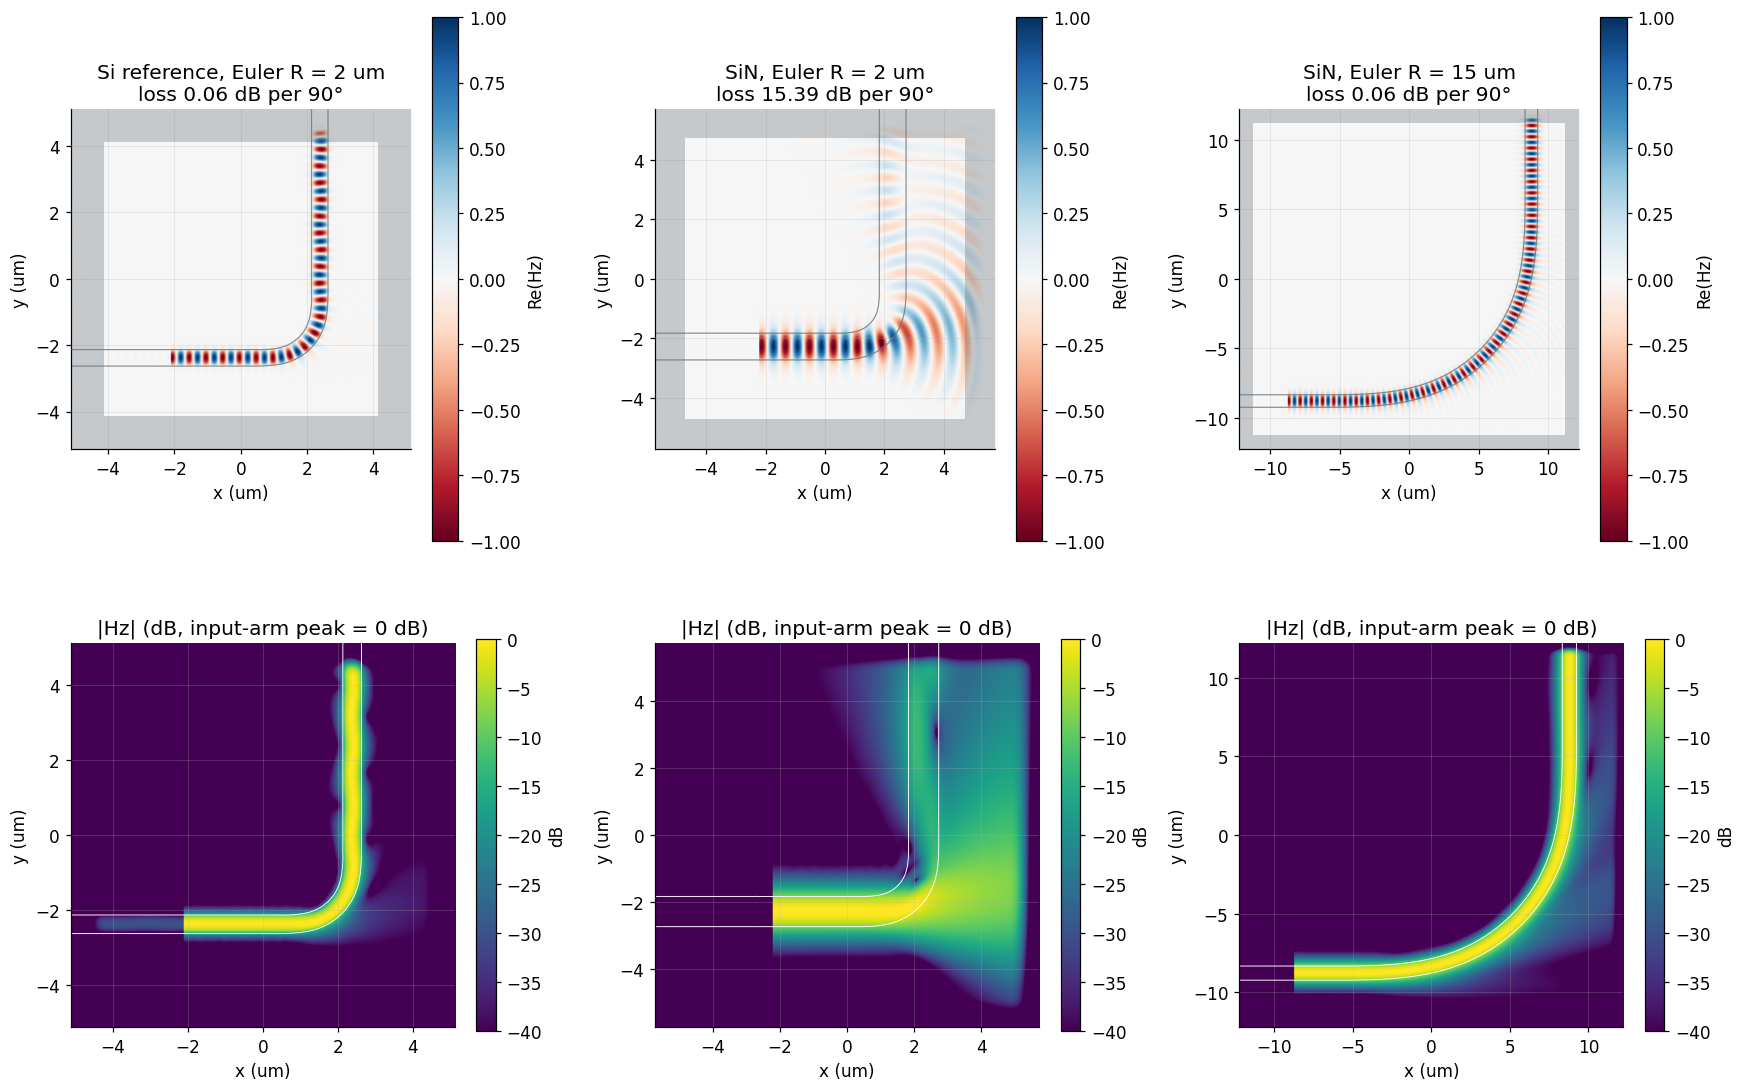

In [21]:
# Normalize each field to its peak on the input arm (x below the o1 port plane), then
# plot Re(Hz) on a shared +-1 scale and |Hz| in dB on a shared -40..0 dB scale.
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for col, (title, p, fs, loss) in enumerate(snaps):
    xmin, xmax, ymin, ymax = fs.extent_um
    nx, ny = fs.field.shape
    xs = np.linspace(xmin, xmax, nx)
    p1c, *_ = bend._port_planes(p)
    norm = np.abs(fs.field[xs < p1c.x, :]).max()
    f = fs.field / norm
    viz.plot_field(f, fs.eps, fs.extent_um, component=fs.component, ax=axes[0, col],
                   pml_um=p["dpml_um"], vmax=1.0)
    axes[0, col].set_title(f"{title}\nloss {loss:.2f} dB per 90°")
    mag_db = 20 * np.log10(np.maximum(np.abs(f), 1e-6))
    im = axes[1, col].imshow(mag_db.T, origin="lower", extent=fs.extent_um, cmap=style.CMAP_DENSITY,
                             vmin=-40, vmax=0)
    axes[1, col].contour(np.linspace(xmin, xmax, nx), np.linspace(ymin, ymax, ny), fs.eps.T,
                         levels=[(p["core_index"] ** 2 + p["clad_index"] ** 2) / 2],
                         colors="white", linewidths=0.6)
    axes[1, col].set_xlabel("x (um)"); axes[1, col].set_ylabel("y (um)")
    axes[1, col].set_title("|Hz| (dB, input-arm peak = 0 dB)")
    plt.colorbar(im, ax=axes[1, col], fraction=0.046, label="dB")
fig.tight_layout()
plt.show()

**Reading.**
- **Left:** the Si reference at R = 2 µm stays guided (0.06 dB). The leak is only visible
  in the dB map, below −25 dB, as a faint tangential beam off the arc.
- **Middle:** SiN at the same radius loses 15 dB. The mode tail (1/γ = 0.25 µm) reaches the
  radiation caustic $x_t = R(n_\mathrm{eff}/n_\mathrm{clad}-1) = 0.33$ µm. That lies
  *inside* the core half-width of 0.45 µm, so there is no barrier at all, and the field
  sheds into the cladding as wavefronts that fill the outer half of the cell.
- **Right:** SiN reaches the same 0.06 dB only at R = 15 µm, 7.5× the Si radius. Its
  caustic is then 2.45 µm from the centre line, so the mode tunnels through about 2 µm of
  cladding before leaking.
- The equal-loss radius ratio from these Euler snapshots (7.5× between swept points)
  agrees with the interpolated 8.0–8.1× of Section 9.3.

### 9.5 Why the ratio is what it is: tunnelling to the radiation caustic

Outside the core of a bend of radius $R$, the field obeys Bessel's equation with angular
order $\nu = \beta R$. With $x$ the distance outward from the guide centre line, its local
radial wavenumber is real only where $k_0 n_\mathrm{clad} > \nu/(R+x)$. That happens beyond
the **radiation caustic** $x_t = R\,(n_\mathrm{eff}/n_\mathrm{clad} - 1)$, where the
cladding can carry the mode's angular phase velocity, so the field leaks out there. Before
it gets there, it must tunnel through the barrier between the guide's outer edge $w/2$ and
$x_t$. The WKB tunnelling exponent of the radiated power is

$$\Phi(R) = 2\int_{w/2}^{x_t} \sqrt{\left(\frac{\beta R}{R+x}\right)^2 - k_0^2 n_\mathrm{clad}^2}\;dx,$$

and the radiated fraction per unit angle scales as $e^{-\Phi}$. The often-quoted
conformal-map integrand $\sqrt{\beta^2 - k_0^2 n_\mathrm{clad}^2(1+x/R)^2}$ is larger than
this by the factor $1+x/R$. That factor reaches $n_\mathrm{eff}/n_\mathrm{clad}$ at the
caustic: 1.86 in Si but only 1.16 in SiN, so using it would bias the comparison against
Si. For $x_t \gg w/2$, the exact form reduces to Marcuse's slab result,
$\alpha \propto \exp(-cR)$ with $c = 2\gamma^3/(3\beta^2)$ (D. Marcuse, *Bell Syst. Tech.
J.* 50, 2551 (1971)). Here $\gamma$ is the cladding decay constant from notebook 01.

- **Si reference:** $c$ = 4.95 µm⁻¹.
- **SiN:** $c$ = 0.694 µm⁻¹.
- **Predicted radius ratio at equal radiation loss:** 7.1×.

The plot below draws the measured loss of both platforms against $\Phi(R)$, using each
platform's own $n_\mathrm{eff}$ and width. If tunnelling to the caustic sets the loss, the
radiation-dominated points of the two platforms fall close to one line. The circular
bends' junction loss and the TE1 ripple are not described by $\Phi$.

Si reference: n_eff 2.6713, Marcuse c = 4.952 /um; Phi at its radii: 0.75->3.0, 1->5.2, 1.25->7.5, 1.5->9.8, 1.75->12.1, 2->14.4, 2.5->19.1, 3->23.9, 4->33.4


SiN: n_eff 1.6753, Marcuse c = 0.694 /um; Phi at its radii: 5->1.2, 6->1.9, 8->3.4, 10->5.0, 12->6.6, 15->9.0, 20->13.1, 25->17.2, 30->21.4


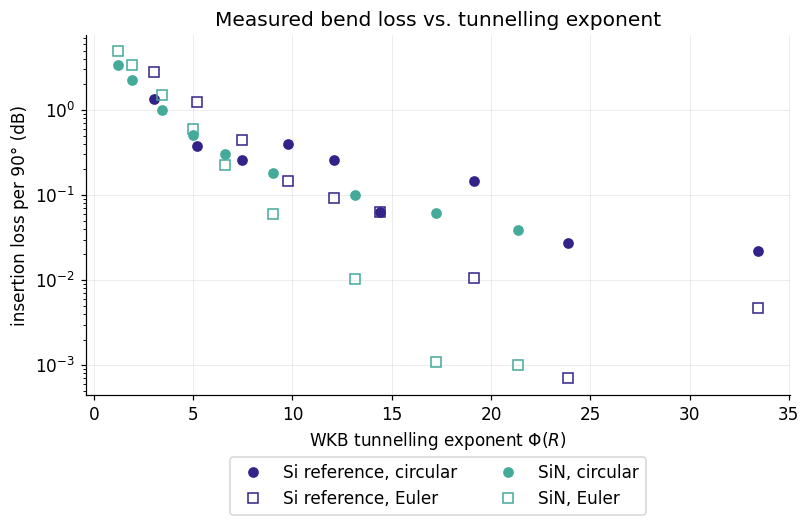

In [22]:
# WKB tunnelling exponent Phi(R) per platform (2D n_eff = the calibrated cross-section
# n_eff), and the measured loss of both platforms against it.
def wkb_exponent(R, n_eff, n_clad, width, wl=1.35):
    k0 = 2 * np.pi / wl
    beta = k0 * n_eff
    x_t = R * (n_eff / n_clad - 1)
    if x_t <= width / 2:
        return 0.0
    integrand = lambda x: np.sqrt(max((beta * R / (R + x)) ** 2 - (k0 * n_clad) ** 2, 0.0))
    return 2 * quad(integrand, width / 2, x_t)[0]

platforms = {
    "Si reference": dict(width=SI_REF_PARAMS["wg_width_um"], n_core=SI_REF_PARAMS["core_index"], radii=SI_REF_RADII_UM,
                         loss=si_ref_loss, color=style.COLOR_INDIGO),
    "SiN": dict(width=params["wg_width_um"], n_core=params["core_index"], radii=RADIUS_SWEEP_UM,
                loss=loss_db_by_type, color=style.COLOR_TEAL),
}
fig, ax = plt.subplots(figsize=(7.5, 5))
for name, pl in platforms.items():
    n_eff = slab_modes.n_eff_single(wl0, width=pl["width"], n_core=pl["n_core"], n_clad=params["clad_index"], span=8.0)
    phi = np.array([wkb_exponent(r, n_eff, params["clad_index"], pl["width"], wl0) for r in pl["radii"]])
    pl["phi"], pl["n_eff"] = phi, n_eff
    ax.semilogy(phi, np.clip(pl["loss"]["circular"], 1e-4, None), "o", color=pl["color"], label=f"{name}, circular")
    ax.semilogy(phi, np.clip(pl["loss"]["euler"], 1e-4, None), "s", color=pl["color"], mfc="none", label=f"{name}, Euler")
    gamma = 2 * np.pi / wl0 * np.sqrt(n_eff ** 2 - params["clad_index"] ** 2)
    pl["c_marcuse"] = 2 * gamma ** 3 / (3 * (2 * np.pi / wl0 * n_eff) ** 2)
    print(f"{name}: n_eff {n_eff:.4f}, Marcuse c = {pl['c_marcuse']:.3f} /um; Phi at its radii: " + ", ".join(f"{r:g}->{p:.1f}" for r, p in zip(pl["radii"], phi)))
ax.set_xlabel(r"WKB tunnelling exponent $\Phi(R)$")
ax.set_ylabel("insertion loss per 90° (dB)")
ax.set_title("Measured bend loss vs. tunnelling exponent")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
plt.show()

**Reading.**
- **The ratio.** Marcuse's decay constants, c = 4.95 µm⁻¹ (Si) and 0.694 µm⁻¹ (SiN),
  predict a radius ratio of **7.1×** at equal radiation loss. The FDTD gives 7.7–8.1× in
  Section 9.3, a 10 % difference. The order-of-magnitude gap between the platforms is thus
  set by γ³/β², i.e. by the lateral confinement, which scales as Δn_eff^{3/2}.
- **The collapse.** On the Φ axis the Euler points of both platforms fall into the same
  range. 0.01 dB is reached at Φ ≈ 13 (SiN) and Φ ≈ 19 (Si). On the R axis that is 20 µm
  against 2.5 µm. So Φ removes most of the 8× difference, but not all of it:
  - The SiN points fall faster with Φ than the Si points (about 0.50 against 0.32 per unit
    Φ, in the natural log of the loss).
  - The prefactor of $e^{-\Phi}$ (the field at the core edge, the arc length, and for Euler
    bends the varying curvature) differs between the platforms. A leading-order exponent
    cannot capture that.
- **Circular bends.** They leave the trend above Φ ≈ 10: their junction loss, and in Si the
  TE1 ripple, are not tunnelling.

**Why the integrand matters.** The conformal-map integrand overstates the Si barrier by up
to 1.86×. With it, the Si points would sit at about twice the Φ of SiN for equal loss, and
the comparison would look inconsistent for a reason that has nothing to do with physics.

---

## 10. Summary

- **Model.** Both platforms use a 2D effective-index model with an n_eff-matched core:
  SiN 1.7650, Si reference 2.944. Each reproduces the MPB n_eff of its real cross-section,
  900 × 400 nm SiN (1.6753) and 500 × 220 nm Si (2.6713).
- **Benchmarks.** Against published 3D results, the model overestimates bend loss by
  2.6–4.7× (Si, Bahadori 2019 fit; 1.8× against their direct point) and 1.8–2.0× (SiN,
  Pita Ruiz 2025 simulation and measurement). It reproduces the measured Euler-worse-than-
  circular ordering at R = 6 µm. The radii here are therefore conservative, by about 1.5×
  (Si) and 1.25× (SiN).
- **SiN bend at 1.35 µm.**
  - Euler: 0.1 dB from R = 13.8 µm, 0.01 dB from 20.1 µm.
  - Circular: 0.1 dB from 20.1 µm, then limited by junction loss (0.039 dB at 30 µm).
  - The Euler bend is worse than the circular one up to R = 10 µm, and better beyond.
- **Design point.** Euler, R = 20 µm, 0.010 dB per 90° (`sin/data/design_points/sin_bend.yaml`).
  The SAX model is `models.sin_bend`. The circular fit is ±30 % above 20 µm.
- **SiN vs Si.** SiN needs **7.7–8.1× the radius** of the calibrated Si reference for the
  same loss. Marcuse's exp(−2γ³R/3β²) predicts 7.1×, from the lateral decay constants
  3.99 vs 10.47 µm⁻¹. Allowing for the benchmark bias, a 3D estimate is about 7×.
- **Side finding.** The circular Si-reference bend ripples with a period of 1.0 µm in R:
  TE0/TE1 beating in the two-moded 500 nm strip (predicted 1.02 µm).
- **Caveats.**
  - This is 2D: there is no substrate or vertical radiation, and the material is
    non-dispersive.
  - All results are at one wavelength, 1.35 µm.
  - The Si track (core 2.7) is *not* a valid Si reference for bends (lateral n_eff 2.418
    against 2.671). It is shown only in grey.